# Paket C: Datenqualitaet, Bereinigung und Wetter-Join
Enis, Gruppe 4, Teil 1. Zeitraum: 1.1.-31.3.2026.

Wir verwenden Bs Ist-Daten, Haltestellen und DuckDB-Schema. Die wiederverwendbaren
Schritte liegen wie bei B in `src/`; dieses Notebook fuehrt sie aus und zeigt die Befunde.
Vorher die Ingestion und Hoehenergaenzung gemaess README ausfuehren.

Quellen (APA 7): MeteoSchweiz (2026), *Automatische Wetterstationen: Messwerte*,
https://opendatadocs.meteoswiss.ch/a-data-groundbased/a1-automatic-weather-stations ;
SBB/SKI (2026), *Ist-Daten v2*, https://archive.opentransportdata.swiss/actual_data_archive.htm ;
swisstopo (2026), *Height: GeoAdmin API*, https://api3.geo.admin.ch/services/sdiservices.html#height .
Definitionen: Wallroth (2026), `docs/konzept.md`.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'data/raw/.cache/matplotlib'))
import pandas as pd
from IPython.display import display, Markdown, Image
OUT = ROOT / 'docs/ergebnisse'
DB = ROOT / 'data/oev_wetter.duckdb'
pd.set_option('display.max_columns', 12)


## 1. Gemeinsame Regeln umsetzen
Ankunftsverspaetung, nur REAL, keine Ausfaelle/Durchfahrten, -10 bis +60 Minuten.
Der Lauf erstellt zuerst EDA und Ausschlussbilanz, dann Zuordnung und Analyse.
Rohdaten werden nicht veraendert. Erneutes Ausfuehren ersetzt nur die Ergebnisse.

Geeignete Station: mindestens 90% Niederschlags- und Temperaturwerte. Raeumliche Grenzen:
30 km und 500 m. Wetterzeit ist das Ende des Stundenintervalls `(t-1h,t]`.
Der konkrete Code mit Kommentaren steht in `src/transform.py`.

In [2]:
from datetime import date
from transform import transform
parameter = transform(date(2026, 1, 1), date(2026, 3, 31), DB)

{
  "start": "2026-01-01",
  "end": "2026-03-31",
  "niederschlag_q90_mm": 1.7,
  "max_distanz_km": 30.0,
  "max_hoehendiff_m": 500.0,
  "geeignete_stationen": [
    "ARH",
    "BIZ",
    "EBK",
    "GUT",
    "HAI",
    "OBR",
    "RAG",
    "SAE",
    "STG",
    "TAE"
  ],
  "haltestellen_gesamt": 2587,
  "haltestellen_zugeordnet": 2540,
  "halte_analyse": 11626929
}


## 2. Datenqualitaet vor Bereinigung
Ankunftsstatus separat pruefen: Bs Zahlen zu Abfahrten sind hier nicht uebertragbar.
Fehlende Ankuenfte koennen auch Fahrplan-Anfangshalte sein; sie sind nicht automatisch
Datenfehler. Die Ausschlussbilanz ist sequenziell, damit Zeilen nicht doppelt gezaehlt werden.

In [3]:
for name in ['qualitaet_verkehrsmittel', 'qualitaet_kanton', 'ankunftsstatus', 'bereinigung']:
    display(Markdown('**' + name + '**'))
    display(pd.read_csv(OUT / (name + '.csv')))

**qualitaet_verkehrsmittel**

,gruppe,halte,an_real,real_anteil,ankunft_fehlt,ausfaelle,durchfahrten,ausreisser
0,Bahn,1752313,1572220,0.897226,162256,20239,232,1426
1,Bus,15320925,10102557,0.659396,874221,8123,0,2508


**qualitaet_kanton**

,gruppe,halte,an_real,real_anteil,ankunft_fehlt,ausfaelle,durchfahrten,ausreisser
0,AI,143342,128176,0.894197,12967,838,0,16
1,AR,1143369,717424,0.627465,84222,2047,106,453
2,SG,11783513,7281973,0.617980,695927,12786,58,2012
3,TG,4003014,3547204,0.886133,243361,12691,68,1453


**ankunftsstatus**

,verkehrsmittel_gruppe,an_status,halte
0,Bahn,LEER,131597
1,Bahn,PROGNOSE,18659
2,Bahn,REAL,1572220
3,Bahn,UNBEKANNT,29837
4,Bus,GESCHAETZT,3164804
5,Bus,LEER,872036
6,Bus,PROGNOSE,1137624
7,Bus,REAL,10102557
8,Bus,UNBEKANNT,43904


**bereinigung**

,bereinigung,halte
0,1_ankunft_fehlt,1036477
1,2_nicht_gemessen,4361986
2,3_ausfall,904
3,4_durchfahrt,195
4,5_unplausibel,2504
5,7_behalten,11671172


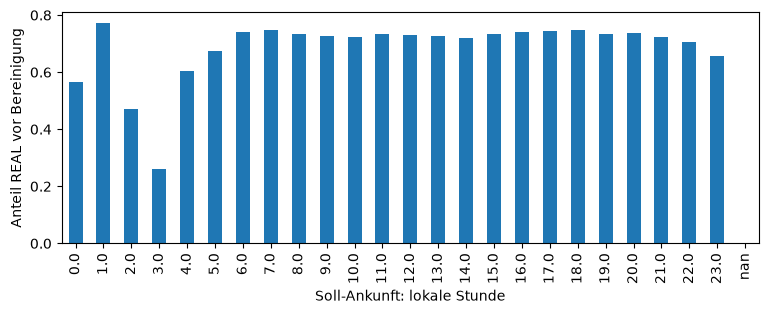

In [4]:
quality = pd.read_csv(OUT / 'qualitaet_stunde.csv')
quality.plot.bar(x='gruppe', y='real_anteil', legend=False, figsize=(9, 3),
                 xlabel='Soll-Ankunft: lokale Stunde', ylabel='Anteil REAL vor Bereinigung');

## 3. Wetterabdeckung und raeumliche Zuordnung
QUI, SCM und STK fehlen die Kernparameter. Die naechste passende Station kann in einem
anderen der vier Kantone liegen. Alle Haltestellenhoehen sind ergaenzte Gelaendehoehen.
47 Haltestellen bleiben ausserhalb der Grenzen. Ein Bergstandort wie Saentis wird nicht
allein wegen seiner Naehe einem tief gelegenen Halt zugeordnet.

In [5]:
display(pd.read_csv(OUT / 'wetterqualitaet.csv'))
display(pd.read_csv(OUT / 'stationszuordnung.csv'))
display(pd.read_csv(OUT / 'join_bilanz.csv'))

,station_abk,stunden_erwartet,stunden_vorhanden,fehlende_zeitstempel,niederschlag_mm_vorhanden,temperatur_c_vorhanden,schneehoehe_cm_vorhanden,wind_kmh_vorhanden
0,ARH,2208,2208,0,2208,2208,2205,2208
1,BIZ,2208,2208,0,2208,2208,0,2208
2,EBK,2208,2208,0,2208,2208,2197,2198
3,GUT,2208,2208,0,2208,2208,0,2208
4,HAI,2208,2208,0,2208,2208,0,2208
5,OBR,2208,2208,0,2208,2208,0,2200
6,QUI,2208,2208,0,0,0,0,2208
7,RAG,2208,2208,0,2208,2208,0,2188
8,SAE,2208,2208,0,2160,2208,0,2208
9,SCM,2208,2208,0,0,0,0,2208


,station_abk,name,hoehe_m,haltestellen,mittlere_distanz_km,max_distanz_km,max_hoehendiff_m
0,ARH,Altenrhein,398.0,154,4.772831,10.037903,493.0
1,BIZ,Bischofszell / Sitterdorf,507.0,279,8.700366,15.411227,288.6
2,EBK,Ebnat-Kappel,623.0,415,12.548706,28.683974,493.8
3,GUT,Güttingen,440.0,166,6.779424,10.423304,119.0
4,HAI,Salen-Reutenen,719.0,209,9.092179,25.386848,325.1
5,OBR,Oberriet / Kriessern,409.0,176,7.278564,21.784875,476.6
6,QUI,Quinten,419.0,0,NaN,NaN,NaN
7,RAG,Bad Ragaz,497.0,248,11.575679,21.975899,482.1
8,SAE,Säntis,2501.0,3,10.644844,21.095650,493.4
9,SCM,Schmerikon,408.0,0,NaN,NaN,NaN


,ergebnis,halte
0,analyse,11626929
1,keine_geeignete_station,44243


## 4. Quantil und abgeleitete Variablen
Das 90. Perzentil wird einmal auf positiven **Stationsstunden vor dem Halt-Join**
berechnet. Fuer den finalen Zeitraum ergibt sich 1,7 mm; stark bedeutet strikt darueber.
HVZ gilt Mo-Fr 06-09 und 16-19 lokal, gesetzliche kantonale Feiertage ausgenommen.
Der Schneeindikator verwendet vorrangig Schneedecke, sonst Niederschlag bei Frost.
Beides bleibt unterscheidbar; Schneehoehe ist kein gemessener aktueller Schneefall.

In [6]:
display(parameter)
display(pd.read_csv(OUT / 'gruppen_verkehrsmittel_gruppe.csv'))
display(pd.read_csv(OUT / 'verspaetung_bereinigt.csv'))

{'start': '2026-01-01',
 'end': '2026-03-31',
 'niederschlag_q90_mm': 1.7,
 'max_distanz_km': 30.0,
 'max_hoehendiff_m': 500.0,
 'geeignete_stationen': ['ARH',
  'BIZ',
  'EBK',
  'GUT',
  'HAI',
  'OBR',
  'RAG',
  'SAE',
  'STG',
  'TAE'],
 'haltestellen_gesamt': 2587,
 'haltestellen_zugeordnet': 2540,
 'halte_analyse': 11626929}

,verkehrsmittel_gruppe,niederschlagsklasse,halte,mittel_min,median_min,verspaetet_anteil
0,Bahn,maessig,204229,1.044172,0.800000,0.071532
1,Bahn,stark,16779,1.073171,0.816667,0.080041
2,Bahn,trocken,1349595,0.831190,0.616667,0.052612
3,Bus,maessig,1362402,1.610878,1.333333,0.154449
4,Bus,stark,120576,1.688480,1.400000,0.165439
5,Bus,trocken,8573348,1.454838,1.233333,0.131099


,verkehrsmittel_gruppe,halte,mittel_min,median_min,p95_min,verspaetet_anteil
0,Bahn,1570603,0.861470,0.65,3.116667,0.055365
1,Bus,10100569,1.478052,1.25,4.300000,0.134794


## 5. Bilanzen und Zeitumstellung kontrollieren
UTC verhindert eine doppelte oder falsche Interpretation der Sommerzeit.
Der lokale 29. Maerz hat 23 Stunden. Wetterluecken duerfen nicht als trocken gelten.
Die Schluessel der Quell- und Zuordnungstabellen verhindern Vervielfachung durch den Join.

In [7]:
import duckdb
with duckdb.connect(str(DB), read_only=True) as con:
    n_source = con.execute('SELECT count(*) FROM halt').fetchall()[0][0]
    n_result, n_missing = con.execute('SELECT count(*), count(*) FILTER (WHERE niederschlag_mm IS NULL OR temperatur_c IS NULL) FROM analyse_halt').fetchall()[0]
    dst_hours = con.execute("SELECT date_diff('hour', timezone('Europe/Zurich','2026-03-29'::DATE::TIMESTAMP), timezone('Europe/Zurich','2026-03-30'::DATE::TIMESTAMP))").fetchall()[0][0]
    display(con.execute("SELECT an_soll, timezone('Europe/Zurich',an_soll) AS lokal, wetter_zeitpunkt FROM analyse_halt WHERE betriebstag='2026-03-29' ORDER BY an_soll LIMIT 5").df())
clean = pd.read_csv(OUT / 'bereinigung.csv')
joined = pd.read_csv(OUT / 'join_bilanz.csv')
assert clean.halte.sum() == n_source
assert joined.halte.sum() == clean.loc[clean.bereinigung == '7_behalten', 'halte'].iloc[0]
assert n_result == parameter['halte_analyse'] and n_missing == 0
assert dst_hours == 23
print(f'Bilanzen stimmen: {n_source:,} Rohhalte -> {n_result:,} Analysehalte. DST: {dst_hours} Stunden.')

C:\Users\enisf\oev-wetter\data\raw\.cache\tmp\ipykernel_19824\3944841093.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  display(con.execute("SELECT an_soll, timezone('Europe/Zurich',an_soll) AS lokal, wetter_zeitpunkt FROM analyse_halt WHERE betriebstag='2026-03-29' ORDER BY an_soll LIMIT 5").df())


,an_soll,lokal,wetter_zeitpunkt
0,2026-03-29 00:06:00+01:00,2026-03-29 00:06:00,2026-03-29 01:00:00+01:00
1,2026-03-29 00:07:00+01:00,2026-03-29 00:07:00,2026-03-29 01:00:00+01:00
2,2026-03-29 00:07:00+01:00,2026-03-29 00:07:00,2026-03-29 01:00:00+01:00
3,2026-03-29 00:08:00+01:00,2026-03-29 00:08:00,2026-03-29 01:00:00+01:00
4,2026-03-29 00:08:00+01:00,2026-03-29 00:08:00,2026-03-29 01:00:00+01:00


Bilanzen stimmen: 17,073,238 Rohhalte -> 11,626,929 Analysehalte. DST: 23 Stunden.


## Ergebnis und Ablage
`analyse_halt` und `analyse_stunde` liegen in DuckDB und als Parquet unter
`data/processed/` (nicht im Repo). Kleine Tabellen und Grafiken liegen unter
`docs/ergebnisse/`. Das zweite Notebook prueft H1-H3; weitere Entscheidungen und
Limitationen stehen in `docs/transformation.md`.